In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
RAW, FIG = ROOT / "data" / "raw", ROOT / "outputs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

pq, csv = RAW / "sim_runs.parquet", RAW / "sim_runs.csv"
if pq.exists():
    df = pd.read_parquet(pq)
elif csv.exists():
    df = pd.read_csv(csv)
else:
    raise FileNotFoundError(f"No dataset in {RAW}. Run notebook 01 first.")
for c in df.select_dtypes("float64").columns:
    df[c] = df[c].astype("float32")

print("loaded:", df.shape)
print("NaNs:", int(df.isna().sum().sum()), "| duplicates:", int(df.duplicated().sum()))
rp = df.groupby("scenario").size(); print("rows per scenario:", rp.min(), "-", rp.max())

df["flood_depth"] = df["flood_depth"].clip(lower=0)
df["inventory"] = df["inventory"].clip(lower=0)
df["fail_isolated"] = df["isolated"] == 1
df["fail_supply"] = df["days_of_supply"] < 0.25
df["fail_shelter"] = df["nearest_shelter_occ"] > 1.0

scn = df.groupby("scenario").agg(peak_rain=("rain_mm", "max"), peak_depth=("flood_depth", "max"),
                                 fail_rate=("failed_now", "mean"))
scn["peak_isolated"] = df.groupby(["scenario", "hour"])["isolated"].sum().groupby("scenario").max()
sev = int(scn["fail_rate"].idxmax()); d = df[df["scenario"] == sev]     # worst scenario

print("\nClass balance:\n", df[["failed_now", "will_fail_within_6h"]].mean().round(3))
df.describe().T.round(2)

In [ ]:
causes = df[["fail_isolated", "fail_supply", "fail_shelter"]].mean().round(3)
print("Share of zone-hours failing, by cause (can overlap):\n", causes)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
causes.plot.bar(ax=ax[0], color=["#d62728", "#ff7f0e", "#1f77b4"], rot=0); ax[0].set_title("Failure cause")
df.loc[df["hours_to_failure"] < 72, "hours_to_failure"].clip(upper=48).plot.hist(bins=48, ax=ax[1], color="#2ca02c")
ax[1].set_title("Hours until failure (uncensored)")
plt.tight_layout(); plt.savefig(FIG / "failure_causes.png", dpi=120); plt.show()

def band(g, ax, title, color):
    ax.fill_between(g.index, g.quantile(0.1, axis=1), g.quantile(0.9, axis=1), alpha=0.25, color=color)
    ax.plot(g.index, g.median(axis=1), color=color, lw=2); ax.set_title(title); ax.set_xlabel("hour")

fig, ax = plt.subplots(1, 4, figsize=(20, 4))
band(df.groupby(["scenario", "hour"])["rain_mm"].mean().unstack("scenario"), ax[0], "Rainfall mm/h", "#1f77b4")
band(df.groupby(["scenario", "hour"])["flood_depth"].mean().unstack("scenario"), ax[1], "Mean flood depth m", "#17becf")
band(df.groupby(["scenario", "hour"])["isolated"].sum().unstack("scenario"), ax[2], "Isolated zones", "#d62728")
band(df.groupby(["scenario", "hour"])["failed_now"].mean().unstack("scenario"), ax[3], "Fraction failed", "#9467bd")
plt.tight_layout(); plt.savefig(FIG / "scenario_curves.png", dpi=120); plt.show()

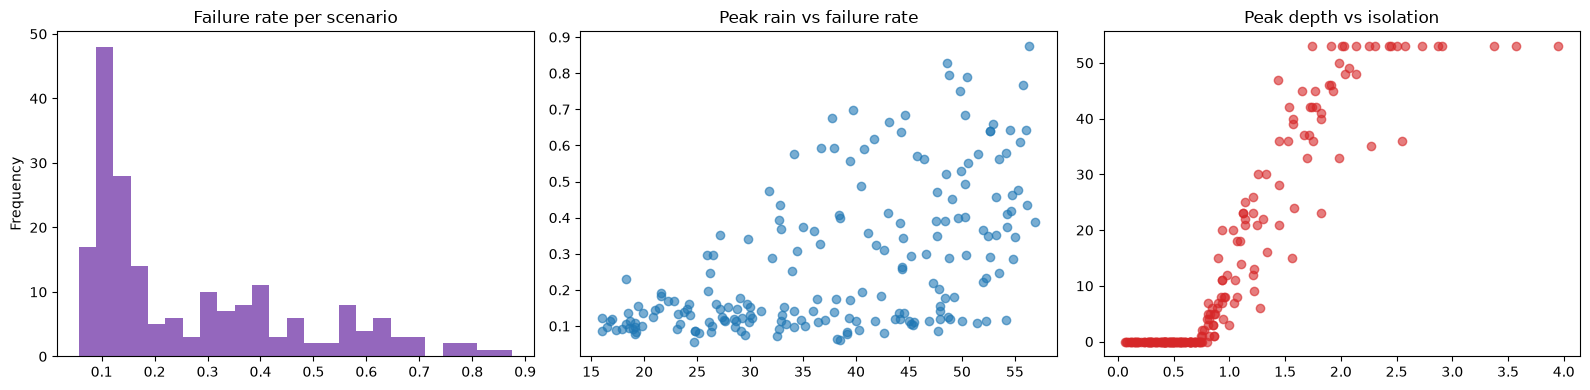

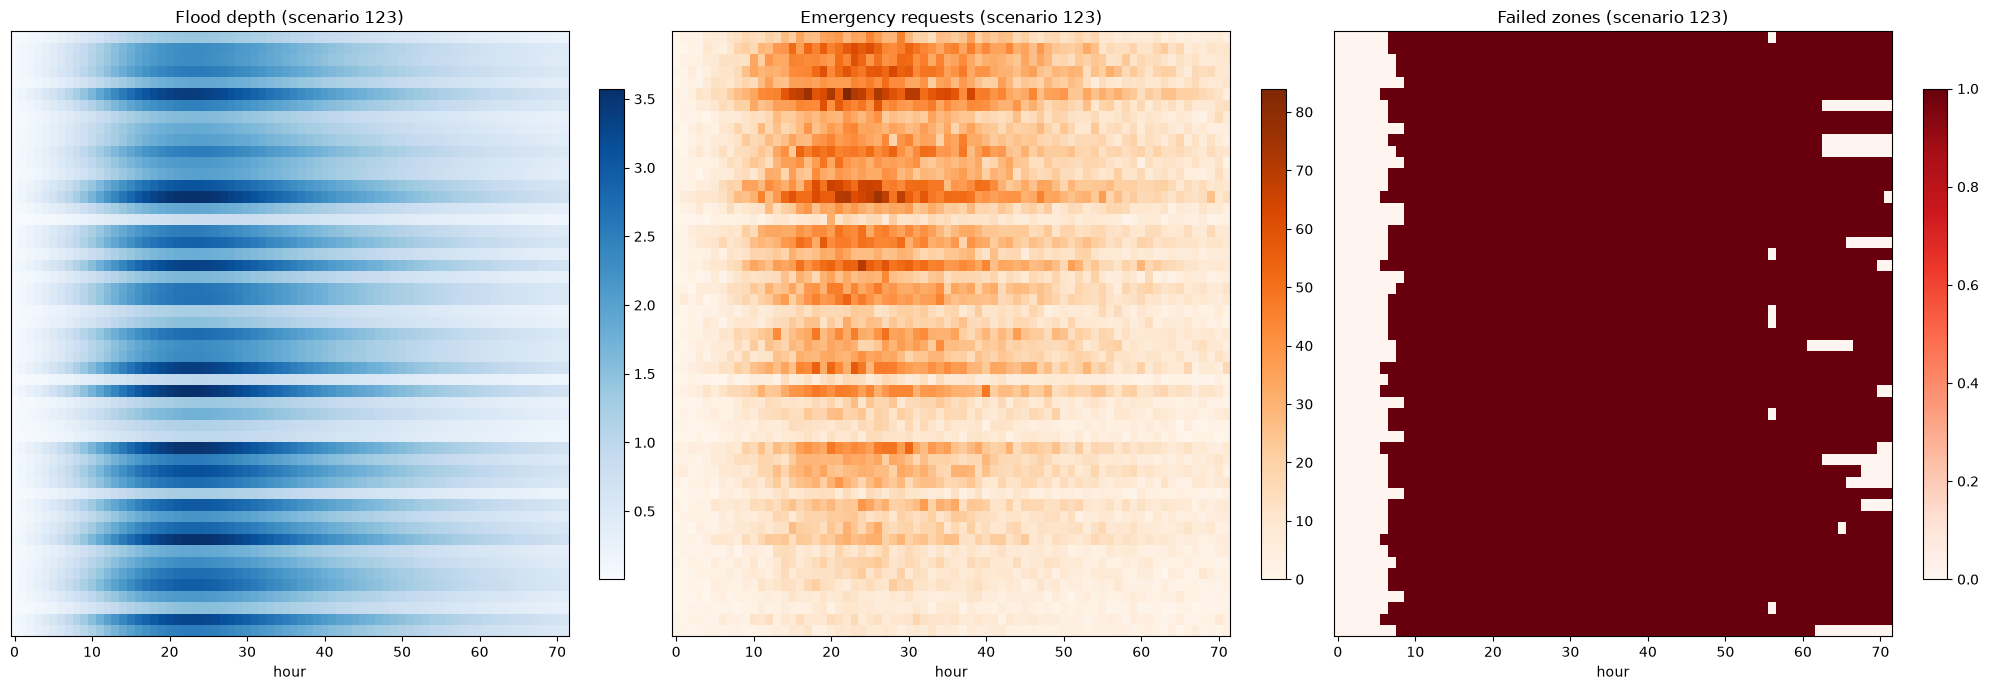

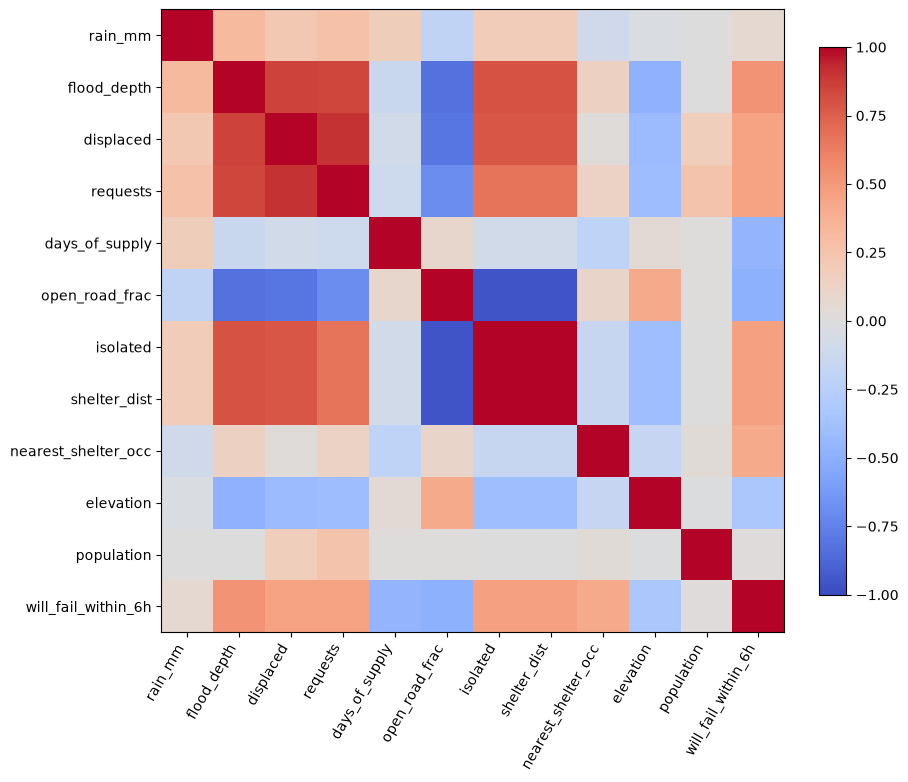

flood_depth            0.529
open_road_frac        -0.485
shelter_dist           0.467
isolated               0.466
days_of_supply        -0.458
displaced              0.451
requests               0.449
nearest_shelter_occ    0.413
elevation             -0.321
rain_mm                0.069
population             0.009
Name: will_fail_within_6h, dtype: float64


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
scn["fail_rate"].plot.hist(bins=25, ax=ax[0], color="#9467bd"); ax[0].set_title("Failure rate per scenario")
ax[1].scatter(scn["peak_rain"], scn["fail_rate"], alpha=0.6); ax[1].set_title("Peak rain vs failure rate")
ax[2].scatter(scn["peak_depth"], scn["peak_isolated"], alpha=0.6, color="#d62728"); ax[2].set_title("Peak depth vs isolation")
plt.tight_layout(); plt.savefig(FIG / "scenario_severity.png", dpi=120); plt.show()

order = d.groupby("node")["population"].first().sort_values(ascending=False).index
fig, ax = plt.subplots(1, 3, figsize=(20, 7))
for a, col, title, cmap in [(ax[0], "flood_depth", "Flood depth", "Blues"),
                            (ax[1], "requests", "Emergency requests", "Oranges"),
                            (ax[2], "failed_now", "Failed zones", "Reds")]:
    im = a.imshow(d.pivot(index="node", columns="hour", values=col).loc[order].values, aspect="auto", cmap=cmap)
    a.set_title(f"{title} (scenario {sev})"); a.set_xlabel("hour"); a.set_yticks([]); plt.colorbar(im, ax=a, fraction=0.04)
plt.tight_layout(); plt.savefig(FIG / "heatmaps.png", dpi=120); plt.show()

cols = ["rain_mm", "flood_depth", "displaced", "requests", "days_of_supply", "open_road_frac",
        "isolated", "shelter_dist", "nearest_shelter_occ", "elevation", "population", "will_fail_within_6h"]
corr = df[cols].corr()
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=60, ha="right")
ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols); plt.colorbar(im, fraction=0.04)
plt.tight_layout(); plt.savefig(FIG / "correlation.png", dpi=120); plt.show()
print(corr["will_fail_within_6h"].drop("will_fail_within_6h").sort_values(key=abs, ascending=False).round(3))